# 01 · Data Preparation

**โปรเจ็ค:** Customer Segmentation & Promotion Strategy สำหรับ Tesco ในสหรัฐฯ
**ข้อมูล:** dunnhumby — *The Complete Journey* (2,500 ครัวเรือน · 102 สัปดาห์)

Notebook นี้ตรวจสอบคุณภาพข้อมูลทุกตาราง ทำความสะอาด และสร้างตัวแปรที่ใช้ต่อใน notebook 02–07
ผลลัพธ์บันทึกไว้ที่ `data/processed/transactions_clean.parquet`

> ไฟล์ข้อมูลดิบอยู่นอก repo ที่ `../data/.parquet/` (กำหนดใน `src/config.py` หรือ env `TESCO_DATA_DIR`)

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.viz import setup, save, seg_palette, PRIMARY, ACCENT, MUTED
setup()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)

In [2]:
from src.data import load, clean_transactions, TABLES
print("DATA_DIR:", config.DATA_DIR)

DATA_DIR: D:\DSI313 Tesco\data\.parquet


## 1. โหลดข้อมูลทุกตาราง
`causal_data` (36.8 ล้านแถว · การจัดวางเด่น/โฆษณาในร้าน) ไม่ได้ใช้ใน scope นี้ จึงไม่โหลด

In [3]:
tables = {name: load(name) for name in TABLES}

overview = pd.DataFrame({
    "rows": {k: len(v) for k, v in tables.items()},
    "columns": {k: v.shape[1] for k, v in tables.items()},
    "null_cells": {k: int(v.isna().sum().sum()) for k, v in tables.items()},
    "duplicate_rows": {k: int(v.duplicated().sum()) for k, v in tables.items()},
})
overview

,rows,columns,null_cells,duplicate_rows
transaction_data,2595732,12,0,0
hh_demographic,801,8,0,0
product,92353,7,0,0
campaign_table,7208,3,0,0
campaign_desc,30,4,0,0
coupon,124548,3,0,5164
coupon_redempt,2318,4,0,0


In [4]:
tx_raw, product = tables["transaction_data"], tables["product"]
tx_raw.head()

,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.00,0.00
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.00,0.00
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.00,0.00
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.00,0.00
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.00,0.00


## 2. ตรวจความถูกต้องของ key ระหว่างตาราง

In [5]:
checks = {
    "households in transactions": tx_raw.household_key.nunique(),
    "transaction products missing in product table": (~tx_raw.PRODUCT_ID.isin(product.PRODUCT_ID)).sum(),
    "households with demographics": tables["hh_demographic"].household_key.nunique(),
    "campaign_table campaigns missing in campaign_desc":
        (~tables["campaign_table"].CAMPAIGN.isin(tables["campaign_desc"].CAMPAIGN)).sum(),
    "redemptions without a matching campaign send":
        len(tables["coupon_redempt"].merge(tables["campaign_table"], on=["household_key", "CAMPAIGN"],
                                           how="left", indicator=True).query("_merge == 'left_only'")),
    "DAY range": f"{tx_raw.DAY.min()} – {tx_raw.DAY.max()}",
    "WEEK_NO range": f"{tx_raw.WEEK_NO.min()} – {tx_raw.WEEK_NO.max()}",
}
pd.Series(checks, name="value").to_frame()

,value
households in transactions,2500
transaction products missing in product table,0
households with demographics,801
campaign_table campaigns missing in campaign_desc,0
redemptions without a matching campaign send,0
DAY range,1 – 711
WEEK_NO range,1 – 102


**ผล:** key ทุกตารางเชื่อมกันได้ครบ ไม่มีสินค้าหรือแคมเปญที่หาคู่ไม่เจอ และไม่มีแถวซ้ำ
ข้อมูลประชากรมีเพียง **801 จาก 2,500 ครัวเรือน (32%)** จึงใช้เป็นข้อมูลอธิบายกลุ่มเท่านั้น ไม่ใช้เป็น feature ในการ cluster

## 3. ค่าผิดปกติใน transaction
- `QUANTITY = 0` หรือ `SALES_VALUE <= 0` คือรายการที่ไม่มีการขายจริง (คืนสินค้า/ปรับยอด/ส่วนลดเต็มจำนวน)
- ส่วนลด (`RETAIL_DISC`, `COUPON_DISC`, `COUPON_MATCH_DISC`) เก็บเป็นค่าติดลบ

In [6]:
bad = pd.Series({
    "QUANTITY == 0": (tx_raw.QUANTITY == 0).sum(),
    "SALES_VALUE <= 0": (tx_raw.SALES_VALUE <= 0).sum(),
    "either (rows to drop)": ((tx_raw.QUANTITY <= 0) | (tx_raw.SALES_VALUE <= 0)).sum(),
})
bad_sales = tx_raw.loc[(tx_raw.QUANTITY <= 0) | (tx_raw.SALES_VALUE <= 0), "SALES_VALUE"].sum()
display(bad.to_frame("rows"))
print(f"share of rows dropped: {bad.iloc[2] / len(tx_raw):.2%} · sales in dropped rows: ${bad_sales:,.0f}")
tx_raw[["QUANTITY", "SALES_VALUE", "RETAIL_DISC", "COUPON_DISC", "COUPON_MATCH_DISC"]].describe().T

,rows
QUANTITY == 0,14466
SALES_VALUE <= 0,18850
either (rows to drop),18917


share of rows dropped: 0.73% · sales in dropped rows: $19


,count,mean,std,min,25%,50%,75%,max
QUANTITY,"2,595,732.00",100.43,"1,153.44",0.00,1.00,1.00,1.00,"89,638.00"
SALES_VALUE,"2,595,732.00",3.10,4.18,0.00,1.29,2.00,3.49,840.00
RETAIL_DISC,"2,595,732.00",-0.54,1.25,-180.00,-0.69,-0.01,0.00,3.99
COUPON_DISC,"2,595,732.00",-0.02,0.22,-55.93,0.00,0.00,0.00,0.00
COUPON_MATCH_DISC,"2,595,732.00",-0.00,0.04,-7.70,0.00,0.00,0.00,0.00


## 4. ทำความสะอาดและสร้างตัวแปร
ใช้ฟังก์ชัน `clean_transactions()` ใน `src/data.py`:

| ขั้นตอน | รายละเอียด |
|---|---|
| ตัดแถว | `QUANTITY = 0` หรือ `SALES_VALUE <= 0` |
| เชื่อมสินค้า | `DEPARTMENT`, `BRAND` (National / Private), `COMMODITY_DESC` |
| flag | `is_non_merch` = น้ำมัน (`KIOSK-GAS`) และ `MISC. TRANS.` — เก็บไว้แต่แยกวิเคราะห์ได้ |
| ส่วนลด | แปลงเป็นค่าบวก: `retail_disc`, `coupon_disc`, `coupon_match_disc`, `discount_total` |
| โปรโมชัน | `on_promo` = ซื้อตอนมีส่วนลดหน้าร้าน · `used_coupon` = ใช้คูปอง |
| เวลา | `hour` จาก `TRANS_TIME` (HHMM) |

In [7]:
tx = clean_transactions(tx_raw, product)
print(f"rows: {len(tx_raw):,} -> {len(tx):,}")
print(f"sales: ${tx_raw.SALES_VALUE.sum():,.0f} -> ${tx.SALES_VALUE.sum():,.0f}")
assert tx.household_key.nunique() == 2500
assert tx.DEPARTMENT.notna().all()
tx.head()

rows: 2,595,732 -> 2,576,815
sales: $8,057,463 -> $8,057,444


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,...,COMMODITY_DESC,is_non_merch,retail_disc,coupon_disc,coupon_match_disc,discount_total,on_promo,used_coupon,hour,weekday
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,...,POTATOES,False,0.60,0.00,0.00,0.60,True,False,16,1
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,...,ONIONS,False,0.00,0.00,0.00,0.00,False,False,16,1
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,...,VEGETABLES - ALL OTHERS,False,0.30,0.00,0.00,0.30,True,False,16,1
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,...,TROPICAL FRUIT,False,0.00,0.00,0.00,0.00,False,False,16,1
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,...,ORGANICS FRUIT & VEGETABLES,False,0.39,0.00,0.00,0.39,True,False,16,1


## 5. ช่วงเริ่มต้นของข้อมูล (onboarding)
ครัวเรือนไม่ได้เริ่มซื้อพร้อมกันตั้งแต่วันแรก — ถ้าไม่คำนึงถึง ลูกค้าที่เข้าระบบช้าจะดูเหมือนซื้อน้อย

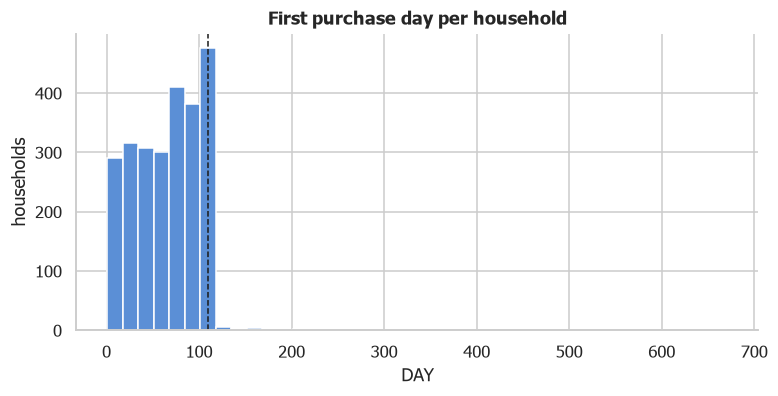

count   2,500.00
mean       66.00
std        40.00
min         1.00
50%        69.00
90%       110.00
99%       118.00
max       671.00
Name: DAY, dtype: float64


In [8]:
first_day = tx.groupby("household_key").DAY.min()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(first_day, bins=40, color=PRIMARY)
ax.axvline(first_day.quantile(0.9), color="k", ls="--", lw=1)
ax.set(title="First purchase day per household", xlabel="DAY", ylabel="households")
save(fig, "01_first_purchase_day")
plt.show()
print(first_day.describe(percentiles=[.5, .9, .99]).round(0))

**ผล:** 90% ของครัวเรือนเริ่มซื้อภายในวันที่ ~110 (สัปดาห์ที่ 16)
- การวัด Frequency จึงต้องหารด้วยระยะเวลาที่เป็นลูกค้า (`baskets_per_week`) ด้วย
- การเทียบยอดซื้อตามเวลา (Q1) จะเริ่มจาก **สัปดาห์ที่ 17** เป็นต้นไป

In [9]:
out = config.PROCESSED_DIR / "transactions_clean.parquet"
tx.to_parquet(out, index=False)
print("saved", out, f"({out.stat().st_size / 1e6:.1f} MB)")

saved D:\DSI313 Tesco\Tesco-Customer-Segmentation\data\processed\transactions_clean.parquet (32.4 MB)


## สรุป Data Preparation
- ตัด **18,917 แถว (0.7%)** ที่ไม่ใช่การขายจริง — ยอดขายรวมแทบไม่เปลี่ยน (~$8.06M)
- key ระหว่างตารางสมบูรณ์ ไม่มี null · ตาราง `coupon` มี **5,164 แถวซ้ำ** (คูปอง–สินค้า–แคมเปญเดียวกัน) จึงนับคูปองด้วย `nunique`
- ข้อจำกัด: ข้อมูลประชากรมี 32% ของครัวเรือนและถูกปิดชื่อตัวแปร · ไม่มีข้อมูลต้นทุน/กำไร · ไม่รู้วันในสัปดาห์จริง